In [38]:
import torchvision
import torch
from torch.utils.data import DataLoader
import torchvision.datasets as datasets
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt
mnist_trainset = datasets.MNIST(root='./data', train=True, download=True, transform=None)
mnist_testset = datasets.MNIST(root='./data', train=False, download=True, transform=None)

train_loader = DataLoader(mnist_trainset, batch_size=64, shuffle=True)
test_loader = DataLoader(mnist_testset, batch_size=64)

In [39]:
train_image_zero, train_target_zero = mnist_trainset[0]
# train_image_zero.show()
print(train_target_zero)

5


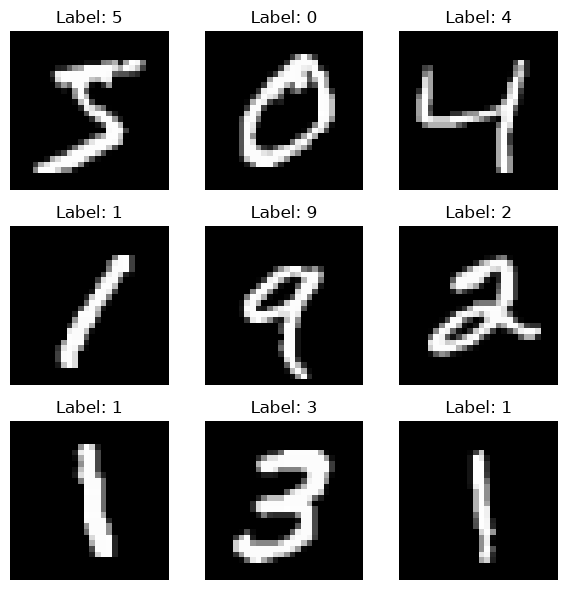

In [40]:
sample_imgs = mnist_trainset[9]
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    img, label = mnist_trainset[i]
    
    ax.imshow(img, cmap='gray')
    ax.set_title(f"Label: {label}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [41]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 64)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # 28x28 → 14x14
        x = self.pool(F.relu(self.conv2(x)))  # 14x14 → 7x7
        x = x.view(-1, 64 * 7 * 7)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = CNN()

In [42]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(10):
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Epoch {epoch+1}, Loss: {running_loss:.3f}, Accuracy: {100 * correct / total:.2f}%")



TypeError: default_collate: batch must contain tensors, numpy arrays, numbers, dicts or lists; found <class 'PIL.Image.Image'>

In [4]:
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import torch
from torch import nn
import sys
from torch import save
from torch.optim import Adam
from torch.nn import CrossEntropyLoss


import matplotlib.pyplot as plt
def get_data_loader(batch_size=32):
    train_data = datasets.MNIST(root="data", train=True, download=True, transform=ToTensor())
    return DataLoader(train_data, batch_size=batch_size, shuffle=True)


class ImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3),  # Output: 26x26
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3), # Output: 24x24
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3), # Output: 22x22
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 22 * 22, 10)       # Fully connected layer for 10 classes
        )

    def forward(self, x):
        return self. Model(x)
def train_model(epochs=10, lr=1e-3, device="mps"):
    loss_history = []  # List to track losses
    model = ImageClassifier().to(device)
    optimizer = Adam(model.parameters(), lr=lr)
    loss_fn = CrossEntropyLoss()
    data_loader = get_data_loader()

    for epoch in range(epochs):
        total_loss = 0
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
        epoch_loss = total_loss/len(data_loader)
        loss_history.append(epoch_loss)  # Append epoch loss to history
        print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss}")

    # torch.save(model.state_dict(), "model_state.pt")
    with open('model_state.pt', 'wb') as f: 
        save(model.state_dict(), f)
    print("Training complete! Model saved as 'model_state.pt'.")
    
    # Plot loss curve
    plt.plot(range(1, epochs + 1), loss_history, marker='o')
    plt.title("Training Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.grid()
    plt.savefig("training_loss_curve.png")
    plt.show()
if __name__ == "__main__":
    # Device setup
    device = get_device()
    epochs_count = int(sys.argv[1]) if len(sys.argv) > 1 else 10
    print(f"Using device: {device}")
    train_model(epochs=epochs_count,device=device)

NameError: name 'get_device' is not defined